In [2]:

import pandas as pd
from pathlib import Path
import json

# Load baseline and group-weighted results
results_path = (
    Path("frozen_experiment_2026-10-14")
    / "results"
    / "test_metrics.csv"
)

results = pd.read_csv(results_path)

# Load balanced-sampling results
balanced_path = Path("results") / "balanced_sampling_test_metrics.json"

with open(balanced_path, "r", encoding="utf-8") as f:
    balanced = json.load(f)

print("=== Existing experiment results ===")
print(results.to_string(index=False))

print("\n=== Balanced-sampling test results ===")
print(json.dumps(balanced, indent=2))


=== Existing experiment results ===
                   Metric  Baseline  Group-weighted
    Overall test accuracy  0.532620        0.547463
Worst-group test accuracy  0.074766        0.393792
         Group 0 accuracy  0.932151        0.689579
         Group 1 accuracy  0.178714        0.393792
         Group 2 accuracy  0.074766        0.414330
         Group 3 accuracy  0.830218        0.721184

=== Balanced-sampling test results ===
{
  "experiment": "group_balanced_sampling",
  "best_epoch": 12,
  "best_worst_group_validation_accuracy": 0.5064377784729004,
  "test_accuracy": 0.553676187992096,
  "worst_group_test_accuracy": 0.4753880202770233,
  "group_accuracy": {
    "0": 0.586696207523346,
    "1": 0.4753880202770233,
    "2": 0.5825545191764832,
    "3": 0.6838006377220154
  }
}


Three-model test comparison:


,Baseline,Group-weighted,Balanced sampling
Overall accuracy,0.5326,0.5475,0.5537
Worst-group accuracy,0.0748,0.3938,0.4754
Group 0,0.9322,0.6896,0.5867
Group 1,0.1787,0.3938,0.4754
Group 2,0.0748,0.4143,0.5826
Group 3,0.8302,0.7212,0.6838


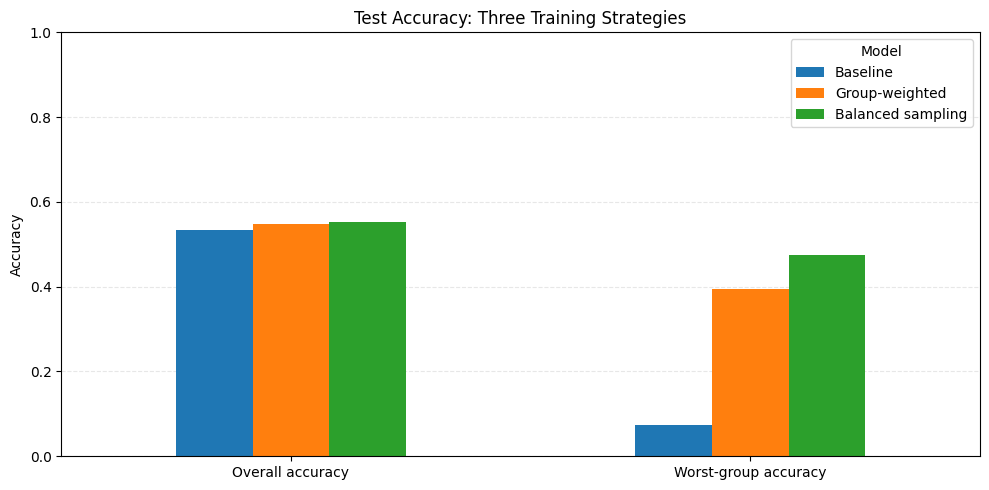

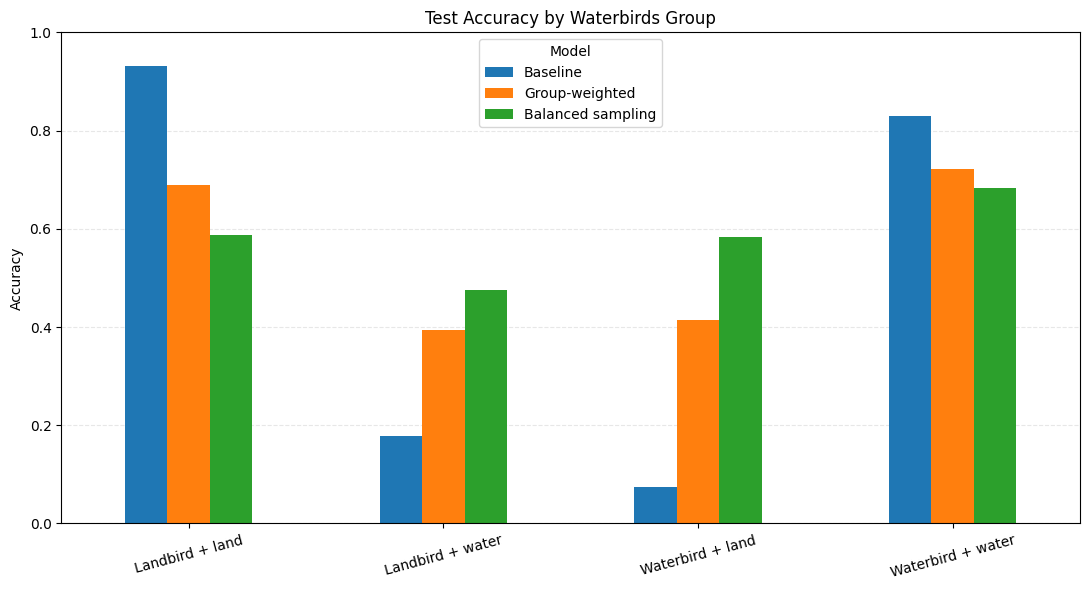

In [5]:

import matplotlib.pyplot as plt
import pandas as pd
import json
from pathlib import Path

# --------------------------------------------------
# 1. Load results
# --------------------------------------------------

results_dir = Path("frozen_experiment_2026-10-14") / "results"
results = pd.read_csv(results_dir / "test_metrics.csv")

balanced_path = Path("results") / "balanced_sampling_test_metrics.json"
with open(balanced_path, "r", encoding="utf-8") as f:
    balanced = json.load(f)

# Convert the CSV to a lookup dictionary
existing = results.set_index("Metric")

# Build one consistent comparison table
comparison = pd.DataFrame({
    "Baseline": [
        existing.loc["Overall test accuracy", "Baseline"],
        existing.loc["Worst-group test accuracy", "Baseline"],
        existing.loc["Group 0 accuracy", "Baseline"],
        existing.loc["Group 1 accuracy", "Baseline"],
        existing.loc["Group 2 accuracy", "Baseline"],
        existing.loc["Group 3 accuracy", "Baseline"],
    ],
    "Group-weighted": [
        existing.loc["Overall test accuracy", "Group-weighted"],
        existing.loc["Worst-group test accuracy", "Group-weighted"],
        existing.loc["Group 0 accuracy", "Group-weighted"],
        existing.loc["Group 1 accuracy", "Group-weighted"],
        existing.loc["Group 2 accuracy", "Group-weighted"],
        existing.loc["Group 3 accuracy", "Group-weighted"],
    ],
    "Balanced sampling": [
        balanced["test_accuracy"],
        balanced["worst_group_test_accuracy"],
        balanced["group_accuracy"]["0"],
        balanced["group_accuracy"]["1"],
        balanced["group_accuracy"]["2"],
        balanced["group_accuracy"]["3"],
    ],
}, index=[
    "Overall accuracy",
    "Worst-group accuracy",
    "Group 0",
    "Group 1",
    "Group 2",
    "Group 3",
])

print("Three-model test comparison:")
display(comparison.round(4))

# --------------------------------------------------
# 2. Overall and worst-group accuracy
# --------------------------------------------------

summary = comparison.loc[
    ["Overall accuracy", "Worst-group accuracy"]
]

ax = summary.plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
ax.set_title("Test Accuracy: Three Training Strategies")
ax.legend(title="Model")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    "frozen_experiment_2026-10-14/overall_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 3. Accuracy across all four groups
# --------------------------------------------------

group_results = comparison.loc[
    ["Group 0", "Group 1", "Group 2", "Group 3"]
].copy()

group_results.index = [
    "Landbird + land",
    "Landbird + water",
    "Waterbird + land",
    "Waterbird + water",
]

ax = group_results.plot(
    kind="bar",
    figsize=(11, 6),
    rot=15
)

ax.set_ylabel("Accuracy")
ax.set_ylim(0, 1)
ax.set_title("Test Accuracy by Waterbirds Group")
ax.legend(title="Model")
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(
    "frozen_experiment_2026-10-14/group_comparison.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
